# Xây dựng và huấn luyện mô hình dự đoán điểm đánh giá Olist

Notebook tạo dữ liệu ở **mức đơn hàng** từ các bảng sạch trong `data/processed`, đánh giá mô hình trên dữ liệu giữ riêng theo thời gian, sau đó fit lại mô hình được chọn bằng **toàn bộ đơn hàng có nhãn** và lưu pipeline để tái sử dụng.

## Có cần dùng hết dữ liệu sạch không?
Không nên ghép mọi bảng/cột một cách máy móc. Cần dùng những dữ liệu có ích và có sẵn tại thời điểm dự đoán, nhưng phải bỏ định danh, dữ liệu trùng cấp sản phẩm và thông tin chỉ phát sinh sau đánh giá. Notebook sử dụng đơn hàng, khách hàng, sản phẩm, dịch danh mục, người bán, thanh toán và vị trí địa lý. Bảng reviews **chỉ** cung cấp nhãn `review_score`; bình luận và thời điểm đánh giá không được làm đặc trưng.

**Thời điểm dự đoán giả định:** sau khi giao hàng, trước khi khách hàng gửi đánh giá. Do đó thời gian giao thực tế được phép dùng. Tập cuối theo thời gian chỉ dùng để đánh giá; mô hình lưu cuối notebook được fit trên toàn bộ đơn hàng có nhãn. Kết quả offline không đảm bảo hiệu quả trên dữ liệu hoặc quy trình khác.

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, mean_absolute_error, mean_squared_error,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
TARGET = "review_score"
SCORES = [1, 2, 3, 4, 5]
sns.set_theme(style="whitegrid")

repo_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "data" / "processed").is_dir()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Không tìm thấy thư mục data/processed của repository.")
data_dir = repo_root / "data" / "processed"
print(f"Repository: {repo_root}")

Repository: D:\FPT UNIVERSITY\Kì 3\ADY201m\ADY291c-AI2107-Group2


## 1. Kết hợp các bảng sạch thành dữ liệu mỗi đơn hàng một dòng

Các bảng items, payments và geolocation có cấp dữ liệu khác nhau nên được tổng hợp trước khi ghép. Tọa độ bưu chính được lấy trung bình theo mã bưu chính; thông tin vị trí người bán được tóm tắt thành tỷ lệ cùng bang và khoảng cách trung bình tới khách hàng. Cách này tránh nhân bản một đơn hàng thành nhiều mẫu.

In [2]:
def read_clean(filename, **kwargs):
    path = data_dir / filename
    if not path.is_file():
        raise FileNotFoundError(f"Thiếu bảng dữ liệu sạch: {path}")
    return pd.read_csv(path, **kwargs)


orders = read_clean(
    "clean_olist_orders.csv",
    parse_dates=["order_purchase_timestamp", "order_delivered_customer_date"],
)
reviews = read_clean("clean_olist_reviews.csv", usecols=["order_id", TARGET])
customers = read_clean("clean_olist_customers.csv")
items = read_clean("clean_olist_order_items.csv")
products = read_clean("clean_olist_products.csv")
translations = read_clean("clean_olist_category_translation.csv")
sellers = read_clean("clean_olist_sellers.csv")
payments = read_clean("clean_olist_payments.csv")
geolocation = read_clean("clean_olist_geolocation.csv")

if reviews["order_id"].duplicated().any():
    raise ValueError("Có nhiều dòng review trên một order_id; cần định nghĩa cách tổng hợp nhãn.")
if customers["customer_id"].duplicated().any():
    raise ValueError("customer_id không duy nhất trong bảng khách hàng.")

geo_by_zip = (
    geolocation.groupby("geolocation_zip_code_prefix", as_index=False)
    .agg(latitude=("geolocation_lat", "mean"), longitude=("geolocation_lng", "mean"))
)
customer_locations = customers.merge(
    geo_by_zip,
    left_on="customer_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left",
    validate="many_to_one",
)

order_base = orders.loc[orders["order_status"].eq("delivered")].copy()
order_base = order_base.merge(
    customer_locations[["customer_id", "customer_state", "latitude", "longitude"]],
    on="customer_id", how="left", validate="one_to_one",
)
order_base = order_base.merge(reviews, on="order_id", how="inner", validate="one_to_one")
order_base["purchase_year"] = order_base["order_purchase_timestamp"].dt.year
order_base["purchase_month"] = order_base["order_purchase_timestamp"].dt.month
order_base["purchase_weekday"] = order_base["order_purchase_timestamp"].dt.dayofweek
order_base["purchase_hour"] = order_base["order_purchase_timestamp"].dt.hour

item_data = items.merge(products, on="product_id", how="left", validate="many_to_one")
item_data = item_data.merge(
    translations, on="product_category_name", how="left", validate="many_to_one"
)
item_data = item_data.merge(sellers, on="seller_id", how="left", validate="many_to_one")
seller_geo = geo_by_zip.rename(columns={
    "geolocation_zip_code_prefix": "seller_zip_code_prefix",
    "latitude": "seller_latitude",
    "longitude": "seller_longitude",
})
item_data = item_data.merge(
    seller_geo, on="seller_zip_code_prefix", how="left", validate="many_to_one"
)
item_data = item_data.merge(
    order_base[["order_id", "customer_state", "latitude", "longitude"]].rename(columns={
        "latitude": "customer_latitude", "longitude": "customer_longitude",
    }),
    on="order_id", how="inner", validate="many_to_one",
)

category_name = item_data["product_category_name_english"].fillna(
    item_data["product_category_name"]
).fillna("unknown")
item_data["product_category"] = category_name.astype(str)
item_data["same_state_seller"] = (
    item_data["customer_state"].eq(item_data["seller_state"]).astype(float)
)
lat1 = np.radians(item_data["customer_latitude"])
lon1 = np.radians(item_data["customer_longitude"])
lat2 = np.radians(item_data["seller_latitude"])
lon2 = np.radians(item_data["seller_longitude"])
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
item_data["seller_distance_km"] = 6371.0 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

item_summary = item_data.groupby("order_id").agg(
    item_count=("order_item_id", "count"),
    distinct_products=("product_id", "nunique"),
    distinct_sellers=("seller_id", "nunique"),
    distinct_categories=("product_category", "nunique"),
    total_item_price=("price", "sum"),
    total_freight_value=("freight_value", "sum"),
    average_item_price=("price", "mean"),
    average_product_photos=("product_photos_qty", "mean"),
    average_product_description_length=("product_description_length", "mean"),
    average_product_weight_g=("product_weight_g", "mean"),
    average_product_volume_cm3=("product_volume_cm3", "mean"),
    same_state_seller_rate=("same_state_seller", "mean"),
    average_seller_distance_km=("seller_distance_km", "mean"),
).reset_index()
item_category = item_data.groupby("order_id")["product_category"].agg(
    lambda values: values.mode().iloc[0] if not values.mode().empty else "unknown"
).rename("main_product_category")
seller_state = item_data.groupby("order_id")["seller_state"].agg(
    lambda values: values.mode().iloc[0] if not values.mode().empty else "unknown"
).rename("main_seller_state")
item_summary = item_summary.merge(item_category, on="order_id", validate="one_to_one")
item_summary = item_summary.merge(seller_state, on="order_id", validate="one_to_one")

payment_summary = payments.groupby("order_id").agg(
    total_payment_value=("payment_value", "sum"),
    max_installments=("payment_installments", "max"),
    payment_transactions_count=("payment_sequential", "count"),
)
payment_type = payments.groupby("order_id")["payment_type"].agg(
    lambda values: values.mode().iloc[0] if not values.mode().empty else "unknown"
).rename("main_payment_type")
payment_summary = payment_summary.join(payment_type).reset_index()

feature_data = order_base.merge(item_summary, on="order_id", how="left", validate="one_to_one")
feature_data = feature_data.merge(
    payment_summary, on="order_id", how="left", validate="one_to_one"
)
feature_data = feature_data.sort_values("order_purchase_timestamp").reset_index(drop=True)
if feature_data["order_id"].duplicated().any():
    raise ValueError("Dữ liệu sau khi ghép không còn ở mức một dòng cho mỗi đơn hàng.")
if not feature_data[TARGET].isin(SCORES).all():
    raise ValueError("Nhãn review_score có giá trị ngoài 1–5 hoặc bị thiếu.")

source_summary = pd.DataFrame({
    "Bảng sạch": [
        "orders", "reviews (chỉ làm nhãn)", "customers", "order_items",
        "products", "category_translation", "sellers", "payments", "geolocation",
    ],
    "Số dòng nguồn": [
        len(orders), len(reviews), len(customers), len(items), len(products),
        len(translations), len(sellers), len(payments), len(geolocation),
    ],
})
display(source_summary)
print(f"Đơn giao thành công có nhãn: {len(feature_data):,}")
print(f"Số order_id duy nhất: {feature_data['order_id'].nunique():,}")
display(feature_data[TARGET].value_counts().sort_index().rename("số đơn hàng").to_frame())

,Bảng sạch,Số dòng nguồn
0,orders,96469
1,reviews (chỉ làm nhãn),95823
2,customers,96469
3,order_items,110186
4,products,32214
5,category_translation,74
6,sellers,2970
7,payments,100744
8,geolocation,19010


Đơn giao thành công có nhãn: 95,823
Số order_id duy nhất: 95,823


,số đơn hàng
review_score,
1,9350
2,2921
3,7916
4,18888
5,56748


## 2. Chọn đầu vào và chia train/validation/test

Không đưa các ID, timestamp gốc, trạng thái sau dự đoán, review/comment hoặc trường dẫn xuất từ review vào model. Chia 20% các đơn hàng mới nhất làm test theo thời gian. Phần 80% lịch sử được chia train/validation có phân tầng để chọn mô hình; test không tham gia chọn mô hình.

In [3]:
numeric_candidates = [
    "delivery_days", "estimated_days", "delay_days", "is_delayed",
    "purchase_year", "purchase_month", "purchase_weekday", "purchase_hour",
    "latitude", "longitude", "item_count", "distinct_products", "distinct_sellers",
    "distinct_categories", "total_item_price", "total_freight_value",
    "average_item_price", "average_product_photos",
    "average_product_description_length", "average_product_weight_g",
    "average_product_volume_cm3", "same_state_seller_rate",
    "average_seller_distance_km", "total_payment_value", "max_installments",
    "payment_transactions_count",
]
categorical_candidates = [
    "customer_state", "main_seller_state", "main_product_category", "main_payment_type",
]
numeric_features = [name for name in numeric_candidates if name in feature_data.columns]
categorical_features = [name for name in categorical_candidates if name in feature_data.columns]
feature_columns = numeric_features + categorical_features
if not feature_columns:
    raise ValueError("Không tìm thấy cột đặc trưng hợp lệ.")

X = feature_data[feature_columns].copy()
y = feature_data[TARGET].astype(int).copy()
split_index = int(len(feature_data) * 0.80)
X_development, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_development, y_test = y.iloc[:split_index], y.iloc[split_index:]
if set(y_development.unique()) != set(SCORES) or set(y_test.unique()) != set(SCORES):
    raise ValueError("Một trong các tập development/test không có đủ 5 mức review_score.")
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development, y_development, test_size=0.20,
    random_state=RANDOM_STATE, stratify=y_development,
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

print(f"Đặc trưng số: {len(numeric_features)} | phân loại: {len(categorical_features)}")
print(f"Train: {len(X_train):,} | validation: {len(X_validation):,} | test: {len(X_test):,}")
print(f"Khoảng thời gian test: {feature_data.iloc[split_index]['order_purchase_timestamp']} → {feature_data.iloc[-1]['order_purchase_timestamp']}")

Đặc trưng số: 26 | phân loại: 4
Train: 61,326 | validation: 15,332 | test: 19,165
Khoảng thời gian test: 2018-05-27 11:41:32 → 2018-08-29 15:00:37


## 3. So sánh baseline và mô hình trên validation

Macro F1 là tiêu chí chọn chính vì dữ liệu lệch mạnh về 5 sao; balanced accuracy, MAE và RMSE giúp diễn giải thêm. Trọng số lớp cân bằng giúp mô hình chú ý hơn tới các điểm ít gặp, nhưng không đảm bảo chúng được dự đoán chính xác.

In [4]:
candidate_estimators = {
    "Baseline (lớp phổ biến)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=1500, random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=160, max_depth=20, min_samples_leaf=4,
        class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1,
    ),
}

validation_rows = []
fitted_candidates = {}
for name, estimator in candidate_estimators.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimator),
    ])
    pipeline.fit(X_train, y_train)
    prediction = pipeline.predict(X_validation)
    fitted_candidates[name] = pipeline
    validation_rows.append({
        "Mô hình": name,
        "Accuracy": accuracy_score(y_validation, prediction),
        "Balanced accuracy": balanced_accuracy_score(y_validation, prediction),
        "Macro F1": f1_score(y_validation, prediction, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_validation, prediction, average="weighted", zero_division=0),
        "MAE (điểm)": mean_absolute_error(y_validation, prediction),
        "RMSE (điểm)": np.sqrt(mean_squared_error(y_validation, prediction)),
    })

validation_results = pd.DataFrame(validation_rows).sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)
display(validation_results.style.format({
    column: "{:.4f}" for column in validation_results.columns if column != "Mô hình"
}))
best_name = validation_results.iloc[0]["Mô hình"]
print(f"Được chọn trên validation theo Macro F1: {best_name}")

,Mô hình,Accuracy,Balanced accuracy,Macro F1,Weighted F1,MAE (điểm),RMSE (điểm)
0,Random Forest,0.5372,0.3176,0.3040,0.5093,0.8576,1.4710
1,Logistic Regression,0.4298,0.3124,0.3038,0.4587,1.0083,1.5168
2,Baseline (lớp phổ biến),0.5789,0.2000,0.1467,0.4245,0.8829,1.5794


Được chọn trên validation theo Macro F1: Random Forest


## 4. Đánh giá tất cả mô hình trên test theo thời gian

Test không được dùng để chọn mô hình. Độ chính xác test phản ánh tốt hơn tình huống dự đoán đơn hàng ở giai đoạn sau của dữ liệu lịch sử.

,Mô hình,Accuracy,Balanced accuracy,Macro F1,Weighted F1,MAE (điểm),RMSE (điểm)
0,Logistic Regression,0.5530,0.2735,0.2718,0.5326,0.8057,1.3989
1,Random Forest,0.6003,0.2665,0.2517,0.5423,0.7580,1.4102
2,Baseline (lớp phổ biến),0.6454,0.2000,0.1569,0.5063,0.6887,1.3550


              precision    recall  f1-score   support

       1 sao       0.28      0.34      0.31      1369
       2 sao       0.04      0.00      0.01       485
       3 sao       0.16      0.02      0.04      1325
       4 sao       0.23      0.11      0.14      3617
       5 sao       0.68      0.86      0.76     12369

    accuracy                           0.60     19165
   macro avg       0.28      0.27      0.25     19165
weighted avg       0.51      0.60      0.54     19165



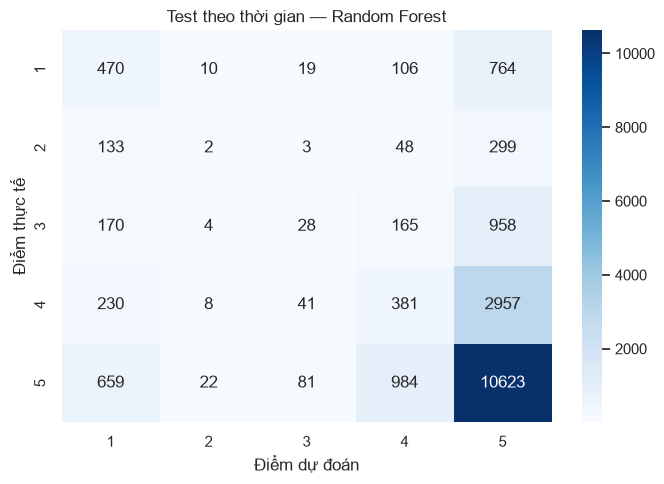

In [5]:
test_rows = []
test_predictions = {}
for name, pipeline in fitted_candidates.items():
    prediction = pipeline.predict(X_test)
    test_predictions[name] = prediction
    test_rows.append({
        "Mô hình": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Balanced accuracy": balanced_accuracy_score(y_test, prediction),
        "Macro F1": f1_score(y_test, prediction, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test, prediction, average="weighted", zero_division=0),
        "MAE (điểm)": mean_absolute_error(y_test, prediction),
        "RMSE (điểm)": np.sqrt(mean_squared_error(y_test, prediction)),
    })
test_results = pd.DataFrame(test_rows).sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(test_results.style.format({
    column: "{:.4f}" for column in test_results.columns if column != "Mô hình"
}))

best_pipeline = fitted_candidates[best_name]
test_prediction = test_predictions[best_name]
best_test_row = test_results.loc[test_results["Mô hình"] == best_name].iloc[0]
test_metrics = {
    "model": best_name,
    "accuracy": float(best_test_row["Accuracy"]),
    "balanced_accuracy": float(best_test_row["Balanced accuracy"]),
    "macro_f1": float(best_test_row["Macro F1"]),
    "weighted_f1": float(best_test_row["Weighted F1"]),
    "mae": float(best_test_row["MAE (điểm)"]),
    "rmse": float(best_test_row["RMSE (điểm)"]),
    "baseline_macro_f1": float(test_results.loc[
        test_results["Mô hình"] == "Baseline (lớp phổ biến)", "Macro F1"
    ].iloc[0]),
}
print(classification_report(
    y_test, test_prediction, labels=SCORES,
    target_names=[f"{score} sao" for score in SCORES], zero_division=0,
))

matrix = confusion_matrix(y_test, test_prediction, labels=SCORES)
plt.figure(figsize=(7, 5))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=SCORES, yticklabels=SCORES)
plt.xlabel("Điểm dự đoán")
plt.ylabel("Điểm thực tế")
plt.title(f"Test theo thời gian — {best_name}")
plt.tight_layout()
plt.show()

## 5. Huấn luyện và lưu model riêng để so sánh

Sau khi đánh giá, fit riêng Random Forest và Baseline trên toàn bộ đơn hàng có nhãn để người dùng có thể nạp và so sánh từng file. Đồng thời vẫn lưu model được chọn theo validation vào file tổng quát. Metric trong metadata lấy từ test giữ riêng, không phải đánh giá trên dữ liệu train cuối.

In [6]:
model_dir = repo_root / "model"
model_dir.mkdir(parents=True, exist_ok=True)

models_to_save = {
    "random_forest": RandomForestClassifier(
        n_estimators=160, max_depth=20, min_samples_leaf=4,
        class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1,
    ),
    "baseline": DummyClassifier(strategy="most_frequent"),
}
saved_model_paths = {}
for model_name, estimator in models_to_save.items():
    full_data_pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimator),
    ])
    full_data_pipeline.fit(X, y)
    path = model_dir / f"review_score_{model_name}.joblib"
    joblib.dump(full_data_pipeline, path)
    saved_model_paths[model_name] = path
    print(f"Đã fit {model_name} bằng {len(X):,} mẫu: {path}")

final_model = clone(best_pipeline)
final_model.fit(X, y)
selected_model_path = model_dir / "review_score_model.joblib"
joblib.dump(final_model, selected_model_path)

for model_name, path in saved_model_paths.items():
    metrics_row = test_results.loc[
        test_results["Mô hình"] == (
            "Random Forest" if model_name == "random_forest" else "Baseline (lớp phổ biến)"
        )
    ].iloc[0]
    model_metadata = {
        "model": model_name,
        "model_file": path.name,
        "target": TARGET,
        "classes": SCORES,
        "training_rows": int(len(X)),
        "feature_columns": feature_columns,
        "numeric_features": numeric_features,
        "categorical_features": categorical_features,
        "prediction_timing": "after delivery, before customer review",
        "test_metrics": {
            "accuracy": float(metrics_row["Accuracy"]),
            "balanced_accuracy": float(metrics_row["Balanced accuracy"]),
            "macro_f1": float(metrics_row["Macro F1"]),
            "weighted_f1": float(metrics_row["Weighted F1"]),
            "mae": float(metrics_row["MAE (điểm)"]),
            "rmse": float(metrics_row["RMSE (điểm)"]),
        },
    }
    path.with_name(path.stem + "_metadata.json").write_text(
        json.dumps(model_metadata, ensure_ascii=False, indent=2), encoding="utf-8"
    )

selected_metadata = {
    "target": TARGET,
    "classes": SCORES,
    "selected_model": best_name,
    "selection_metric": "validation macro F1",
    "training_rows": int(len(X)),
    "feature_columns": feature_columns,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "prediction_timing": "after delivery, before customer review",
    "test_metrics": test_metrics,
    "model_file": selected_model_path.name,
}
(model_dir / "review_score_model_metadata.json").write_text(
    json.dumps(selected_metadata, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(f"Model được chọn theo validation: {selected_model_path}")

Đã fit random_forest bằng 95,823 mẫu: D:\FPT UNIVERSITY\Kì 3\ADY201m\ADY291c-AI2107-Group2\model\review_score_random_forest.joblib


Đã fit baseline bằng 95,823 mẫu: D:\FPT UNIVERSITY\Kì 3\ADY201m\ADY291c-AI2107-Group2\model\review_score_baseline.joblib


Model được chọn theo validation: D:\FPT UNIVERSITY\Kì 3\ADY201m\ADY291c-AI2107-Group2\model\review_score_model.joblib


## 6. Kiểm tra nạp model đã lưu và dự đoán mẫu

Pipeline đã lưu nhận bảng đặc trưng cùng schema bên dưới, không nhận trực tiếp một CSV thô. Khi đưa vào hệ thống thực tế, cần áp dụng cùng logic tổng hợp từ các bảng sạch cho đơn hàng mới.

In [7]:
saved_model = joblib.load(selected_model_path)
loaded_random_forest = joblib.load(saved_model_paths["random_forest"])
loaded_baseline = joblib.load(saved_model_paths["baseline"])
sample_input = X.iloc[[0]].copy()
sample_prediction = int(saved_model.predict(sample_input)[0])
print(f"Số đặc trưng đầu vào: {sample_input.shape[1]}")
print(f"Điểm dự đoán cho một đơn hàng mẫu: {sample_prediction} sao")
print(f"Điểm thực tế của mẫu lịch sử: {int(y.iloc[0])} sao")
print(f"Macro F1 test model được chọn: {test_metrics['macro_f1']:.4f}")
print(f"Random Forest đã lưu: {saved_model_paths['random_forest']}")
print(f"Baseline đã lưu: {saved_model_paths['baseline']}")
print(f"Dự đoán RF / Baseline: {int(loaded_random_forest.predict(sample_input)[0])} / {int(loaded_baseline.predict(sample_input)[0])} sao")

Số đặc trưng đầu vào: 30
Điểm dự đoán cho một đơn hàng mẫu: 4 sao
Điểm thực tế của mẫu lịch sử: 4 sao
Macro F1 test model được chọn: 0.2517
Random Forest đã lưu: D:\FPT UNIVERSITY\Kì 3\ADY201m\ADY291c-AI2107-Group2\model\review_score_random_forest.joblib
Baseline đã lưu: D:\FPT UNIVERSITY\Kì 3\ADY201m\ADY291c-AI2107-Group2\model\review_score_baseline.joblib
Dự đoán RF / Baseline: 4 / 5 sao
